In [1]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.spatial import cKDTree
from shapely.geometry import Point
from utils import generate_incidents

print(sys.executable)

/Users/adegheosaasoro/Downloads/yes/envs/ems-torch/bin/python


In [2]:
population = gpd.read_file(
    "manhattan-data/manhattan_population_blocks.gpkg"
)

facilities = gpd.read_file(
    "manhattan-data/manhattan_hospitals_ems.gpkg"
)

incidents = generate_incidents(
    population,
    n_days=10,
    rate_per_1000_per_day=0.1,
    random_seed=42,
)

if "incident_id" not in incidents.columns:
    incidents.insert(0, "incident_id", incidents.index)

print("Population blocks:", len(population))
print("Facilities:", len(facilities))
print("Incidents:", len(incidents))
print("Population CRS:", population.crs)
print()
print(facilities["asset_type"].value_counts())

Population blocks: 907
Facilities: 9
Incidents: 348
Population CRS: EPSG:2263

asset_type
Hospital       5
EMS station    4
Name: count, dtype: int64


In [3]:
metric_crs = population.estimate_utm_crs()

population_m = population.to_crs(metric_crs)
facilities_m = facilities.to_crs(metric_crs)
incidents_m = incidents.to_crs(metric_crs)

facility_types = (
    facilities_m["asset_type"]
    .fillna("")
    .str.lower()
)

hospitals_m = facilities_m[
    facility_types == "hospital"
].copy()

ems_m = facilities_m[
    facility_types == "ems station"
].copy()

print("Metric CRS:", metric_crs)
print("Hospitals:", len(hospitals_m))
print("EMS stations:", len(ems_m))

Metric CRS: EPSG:32618
Hospitals: 5
EMS stations: 4


In [4]:
study_area = population_m.geometry.union_all()

minx, miny, maxx, maxy = study_area.bounds

spacing = 250

x_coordinates = np.arange(
    minx,
    maxx + spacing,
    spacing,
)

y_coordinates = np.arange(
    miny,
    maxy + spacing,
    spacing,
)

G = nx.grid_2d_graph(
    len(x_coordinates),
    len(y_coordinates),
)

all_positions = {
    node: (
        float(x_coordinates[node[0]]),
        float(y_coordinates[node[1]]),
    )
    for node in G.nodes
}

# Remove nodes outside the Manhattan study area
clipping_area = study_area
outside_nodes = [
    node
    for node, coordinates in all_positions.items()
    if not clipping_area.covers(Point(coordinates))
]

G.remove_nodes_from(outside_nodes)

if G.number_of_nodes() == 0:
    raise ValueError("No graph nodes remained after clipping.")

# Keep the largest connected portion
largest_component = max(
    nx.connected_components(G),
    key=len,
)

G = G.subgraph(largest_component).copy()

positions = {
    node: all_positions[node]
    for node in G.nodes
}

# Add distance weights to the graph edges
for start_node, end_node in G.edges:
    start_x, start_y = positions[start_node]
    end_x, end_y = positions[end_node]

    distance = np.hypot(
        end_x - start_x,
        end_y - start_y,
    )

    G.edges[start_node, end_node]["length_m"] = distance

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print("Connected:", nx.is_connected(G))

Graph nodes: 193
Graph edges: 352
Connected: True


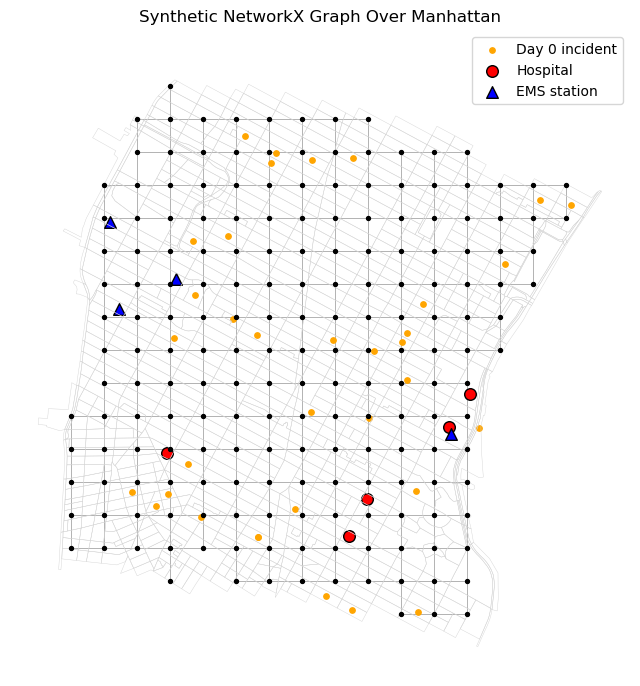

In [5]:
fig, ax = plt.subplots(figsize=(8, 10))

population_m.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.3,
)

nx.draw_networkx_edges(
    G,
    pos=positions,
    ax=ax,
    edge_color="gray",
    width=0.6,
    alpha=0.7,
)

nx.draw_networkx_nodes(
    G,
    pos=positions,
    ax=ax,
    node_color="black",
    node_size=8,
)

incidents_m[
    incidents_m["day"] == 0
].plot(
    ax=ax,
    color="orange",
    markersize=15,
    label="Day 0 incident",
)

hospitals_m.plot(
    ax=ax,
    color="red",
    marker="o",
    edgecolor="black",
    markersize=70,
    label="Hospital",
)

ems_m.plot(
    ax=ax,
    color="blue",
    marker="^",
    edgecolor="black",
    markersize=70,
    label="EMS station",
)

ax.set_title("Synthetic NetworkX Graph Over Manhattan")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend()

plt.show()

In [6]:
node_ids = list(G.nodes)

node_coordinates = np.array([
    positions[node]
    for node in node_ids
])

node_tree = cKDTree(node_coordinates)
def snap_to_graph(points_gdf):
    result = points_gdf.copy()

    point_coordinates = np.column_stack([
        result.geometry.x,
        result.geometry.y,
    ])

    distances, nearest_indices = node_tree.query(
        point_coordinates
    )

    result["nearest_node"] = None

    for row_index, nearest_index in zip(
        result.index,
        nearest_indices,
    ):
        result.at[row_index, "nearest_node"] = (
            node_ids[int(nearest_index)]
        )

    result["snap_distance_m"] = distances

    return result
incidents_m = snap_to_graph(incidents_m)
hospitals_m = snap_to_graph(hospitals_m)
ems_m = snap_to_graph(ems_m)

incidents_m[
    [
        "incident_id",
        "nearest_node",
        "snap_distance_m",
    ]
].head()

,incident_id,nearest_node,snap_distance_m
0,0,"(7, 9)",144.848703
1,1,"(5, 12)",106.495404
2,2,"(5, 11)",108.328983
3,3,"(4, 9)",93.664794
4,4,"(15, 14)",125.628627


In [7]:
def find_best_hospital(origin_node):
    best_result = None

    for hospital_index, hospital in hospitals_m.iterrows():
        destination_node = hospital["nearest_node"]

        try:
            distance = nx.shortest_path_length(
                G,
                source=origin_node,
                target=destination_node,
                weight="length_m",
            )

            route = nx.shortest_path(
                G,
                source=origin_node,
                target=destination_node,
                weight="length_m",
            )

        except nx.NetworkXNoPath:
            continue

        candidate = {
            "hospital_index": hospital_index,
            "hospital_node": destination_node,
            "distance_m": distance,
            "route": route,
        }

        if (
            best_result is None
            or distance < best_result["distance_m"]
        ):
            best_result = candidate

    if best_result is None:
        raise ValueError(
            "No hospital is reachable from this incident."
        )

    return best_result

first_incident = incidents_m.iloc[0]

best_route = find_best_hospital(
    first_incident["nearest_node"]
)

print("Incident ID:", first_incident["incident_id"])
print("Incident node:", first_incident["nearest_node"])
print("Hospital row:", best_route["hospital_index"])
print("Hospital node:", best_route["hospital_node"])
print(
    "Route distance:",
    round(best_route["distance_m"]),
    "meters",
)

Incident ID: 0
Incident node: (7, 9)
Hospital row: 4
Hospital node: (4, 6)
Route distance: 1500 meters


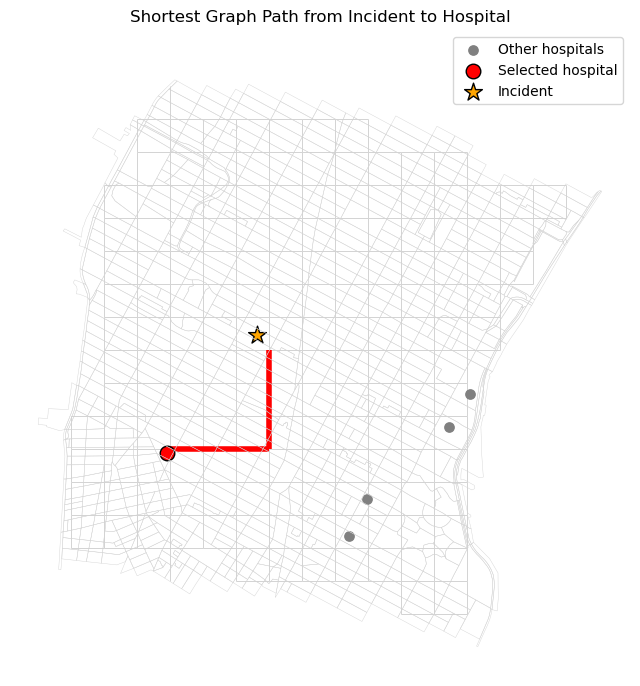

In [8]:
route_nodes = best_route["route"]

route_edges = list(
    zip(
        route_nodes[:-1],
        route_nodes[1:],
    )
)

selected_incident = incidents_m.loc[
    [first_incident.name]
]

selected_hospital = hospitals_m.loc[
    [best_route["hospital_index"]]
]

fig, ax = plt.subplots(figsize=(8, 10))

population_m.boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.3,
)

nx.draw_networkx_edges(
    G,
    pos=positions,
    ax=ax,
    edge_color="lightgray",
    width=0.7,
)

nx.draw_networkx_edges(
    G,
    pos=positions,
    ax=ax,
    edgelist=route_edges,
    edge_color="red",
    width=4,
)

hospitals_m.plot(
    ax=ax,
    color="gray",
    marker="o",
    markersize=45,
    label="Other hospitals",
)

selected_hospital.plot(
    ax=ax,
    color="red",
    marker="o",
    edgecolor="black",
    markersize=110,
    label="Selected hospital",
)

selected_incident.plot(
    ax=ax,
    color="orange",
    marker="*",
    edgecolor="black",
    markersize=180,
    label="Incident",
)

ax.set_title("Shortest Graph Path from Incident to Hospital")
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend()

plt.show()

In [9]:
routing_records = []

for _, incident in incidents_m.iterrows():
    best_route = find_best_hospital(
        incident["nearest_node"]
    )

    routing_records.append({
        "incident_id": incident["incident_id"],
        "day": incident["day"],
        "seconds_since_midnight": (
            incident["seconds_since_midnight"]
        ),
        "incident_node": incident["nearest_node"],
        "hospital_index": best_route["hospital_index"],
        "hospital_node": best_route["hospital_node"],
        "distance_m": best_route["distance_m"],
        "route": best_route["route"],
    })

routing_results = pd.DataFrame(routing_records)

print("Incidents routed:", len(routing_results))
routing_results.head()

Incidents routed: 348


,incident_id,day,seconds_since_midnight,incident_node,hospital_index,hospital_node,distance_m,route
0,0,0,409.656348,"(7, 9)",4,"(4, 6)",1500.0,"[(7, 9), (7, 8), (7, 7), (7, 6), (6, 6), (5, 6..."
1,1,0,800.045149,"(5, 12)",4,"(4, 6)",1750.0,"[(5, 12), (4, 12), (4, 11), (4, 10), (4, 9), (..."
2,2,0,2702.895515,"(5, 11)",4,"(4, 6)",1500.0,"[(5, 11), (5, 10), (5, 9), (5, 8), (5, 7), (5,..."
3,3,0,4093.115328,"(4, 9)",4,"(4, 6)",750.0,"[(4, 9), (4, 8), (4, 7), (4, 6)]"
4,4,0,4196.386643,"(15, 14)",8,"(13, 8)",2000.0,"[(15, 14), (14, 14), (13, 14), (13, 13), (13, ..."


In [10]:
assert len(routing_results) == len(incidents_m)
assert routing_results["hospital_index"].notna().all()
assert routing_results["distance_m"].ge(0).all()

print("All incidents successfully routed.")
print()
print("Route distance summary in meters:")
print(routing_results["distance_m"].describe())

hospital_assignments = (
    routing_results["hospital_index"]
    .value_counts()
    .rename_axis("hospital_index")
    .reset_index(name="incident_count")
)

hospital_assignments


All incidents successfully routed.

Route distance summary in meters:
count     348.000000
mean      998.563218
std       754.667096
min         0.000000
25%       500.000000
50%       750.000000
75%      1250.000000
max      3250.000000
Name: distance_m, dtype: float64


,hospital_index,incident_count
0,4,150
1,3,76
2,5,68
3,8,38
4,7,16


In [11]:
routing_results.drop(
    columns="route"
).to_csv(
    "routing_results.csv",
    index=False,
)

print("Saved routing_results.csv")

Saved routing_results.csv
